# What drives Airbnb prices?

## Technique 1: Simple log-linear OLS regression

$$\ln(\text{Price per night})_i = \beta_0 + \beta_1\,\#\text{beds}_i + \beta_2\,\text{Type}_i + \beta_3\,\text{host years}_i + \beta_4\,\text{Reviews}_i + \beta_5\,\text{Superhost}_i + \beta_6\,\text{max nights}_i + \beta_7\,\text{Monthly stay}_i + \varepsilon_i$$

Room type has 4 categories (Entire home/apt, Private room, Hotel room, Shared room). We include a dummy for each one except **Entire home/apt**, which is the reference group. If all 4 dummies were included alongside the intercept, they would be perfectly collinear with it (the dummy variable trap).

**Minimum stay enters as a yes/no variable.** $\text{Monthly stay}_i = 1$ if the listing requires at least 28 nights, otherwise 0. Toronto's short-term rental rules apply to stays under 28 consecutive nights, so 28 is where the market splits: 52% of the listings we use set their minimum at 28 nights or more, most of them at exactly 28. An earlier version used minimum nights as a straight-line (linear) term. That assumed every extra night of minimum stay changes price by the same %, so it predicted prices of about $2–4 a night for 365-night rentals (see Technique 4). The yes/no variable compares monthly rentals with short-term rentals instead.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = pd.read_csv("listings_clean.csv")
print(df.shape)

(22050, 42)


In [2]:
# CHART STYLE used throughout: reference dataviz palette (blue = series 1, orange = series 2),
# recessive grid and axes, text in ink colours rather than series colours.
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap

C_BASE, C_FLAG = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
    "legend.frameon": False,
})
dollar = mticker.FuncFormatter(lambda v, _: f"${v:,.0f}")

### Data preparation
- `price` is stored as text (e.g. `"$1,250.00"`), so we convert it to a number. Listings without a price are dropped (about 5,300 rows).
- Rows missing `beds` or the min/max-night fields are dropped.
- `maximum_nights` contains placeholder values such as 2,147,483,647. Airbnb's standard maximum is 1,125 nights, so we cap it there.
- `monthly_stay` is 1 when `minimum_nights` ≥ 28 and 0 otherwise.

In [3]:
df["price_num"] = pd.to_numeric(df["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")

cols = ["price_num", "beds", "room_type", "hosts_time_as_host_years",
        "number_of_reviews", "host_is_superhost", "maximum_nights", "minimum_nights"]
data = df[cols].dropna().copy()
data = data[data["price_num"] > 0]

data["maximum_nights"] = data["maximum_nights"].clip(upper=1125)
data["ln_price"] = np.log(data["price_num"])

# Minimum stay as a yes/no variable instead of a linear count of nights.
# 28 nights is Toronto's short-term-rental threshold (rules apply to stays < 28 nights),
# so listings split into short-term rentals (0) and monthly rentals (1).
# A linear term forced each extra night to change price by the same %, which badly
# under-predicted 365-night rentals (prices of ~$2-4 a night).
data["monthly_stay"] = (data["minimum_nights"] >= 28).astype(int)
print(data["monthly_stay"].value_counts().rename({0: "short-term (<28 nights)", 1: "monthly (28+ nights)"}))

print(f"Observations used: {len(data):,} of {len(df):,}")
print(data["room_type"].value_counts())
data.describe().T

monthly_stay
monthly (28+ nights)       8491
short-term (<28 nights)    7972
Name: count, dtype: int64
Observations used: 16,463 of 22,050
room_type
Entire home/apt    11168
Private room        5214
Hotel room            58
Shared room           23
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
price_num,16463.0,237.861102,306.283664,17.310000,90.00000,161.000000,309.665000,9049.100000
beds,16463.0,1.884164,1.166237,1.000000,1.00000,2.000000,2.000000,20.000000
hosts_time_as_host_years,16463.0,4.237077,3.861498,0.000000,1.00000,3.000000,7.000000,15.000000
number_of_reviews,16463.0,37.061410,69.845160,0.000000,2.00000,11.000000,43.000000,1424.000000
host_is_superhost,16463.0,0.415416,0.492809,0.000000,0.00000,0.000000,1.000000,1.000000
maximum_nights,16463.0,490.884772,390.716720,1.000000,200.00000,365.000000,949.500000,1125.000000
minimum_nights,16463.0,17.104598,21.027482,1.000000,1.00000,28.000000,28.000000,365.000000
ln_price,16463.0,5.106525,0.831095,2.851284,4.49981,5.081404,5.735491,9.110421
monthly_stay,16463.0,0.515763,0.499767,0.000000,0.00000,1.000000,1.000000,1.000000


### Estimate the model

In [4]:
# monthly_stay (1 = minimum stay of 28+ nights) replaces the linear minimum_nights term;
# its coefficient is the % price gap between monthly and short-term rentals, all else equal.
formula = ("ln_price ~ beds + C(room_type, Treatment('Entire home/apt')) "
           "+ hosts_time_as_host_years + number_of_reviews + host_is_superhost "
           "+ maximum_nights + monthly_stay")

ols = smf.ols(formula, data=data).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               ln_price   R-squared:                       0.661
Model:                            OLS   Adj. R-squared:                  0.660
Method:                 Least Squares   F-statistic:                     3557.
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:12:17   Log-Likelihood:                -11421.
No. Observations:               16463   AIC:                         2.286e+04
Df Residuals:                   16453   BIC:                         2.294e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                                                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------

### Interpreting the coefficients
In a log-linear model, a one-unit increase in $x$ changes price by about $100\cdot\beta$ %. The exact change is $100\cdot(e^{\beta}-1)$ %, which matters for large coefficients such as the room-type dummies.

In [5]:
results = pd.DataFrame({
    "coef": ols.params,
    "std_err": ols.bse,
    "p_value": ols.pvalues,
    "pct_change_in_price": (np.exp(ols.params) - 1) * 100,
}).drop("Intercept")
results.index = results.index.str.replace(
    r"C\(room_type, Treatment\('Entire home/apt'\)\)\[T\.(.*)\]", r"room: \1", regex=True)
results.round(4)

,coef,std_err,p_value,pct_change_in_price
room: Hotel room,0.0559,0.0641,0.3832,5.7502
room: Private room,-0.7038,0.0089,0.0000,-50.5279
room: Shared room,-0.8094,0.1012,0.0000,-55.4853
beds,0.2089,0.0036,0.0000,23.2268
hosts_time_as_host_years,0.0036,0.0011,0.0011,0.3591
number_of_reviews,-0.0002,0.0001,0.0002,-0.0232
host_is_superhost,-0.0532,0.0081,0.0000,-5.1855
maximum_nights,0.0001,0.0000,0.0000,0.0052
monthly_stay,-0.8699,0.0088,0.0000,-58.1006


### Model performance
The left panel compares each listing's predicted price with its actual price. Points on the dashed line are predicted perfectly. The right panel shows the residuals against a normal curve with the same spread. The residuals are right-skewed and fat-tailed: more listings are far *over* their predicted price than far under. This is why the standard errors are bootstrapped in Technique 2.

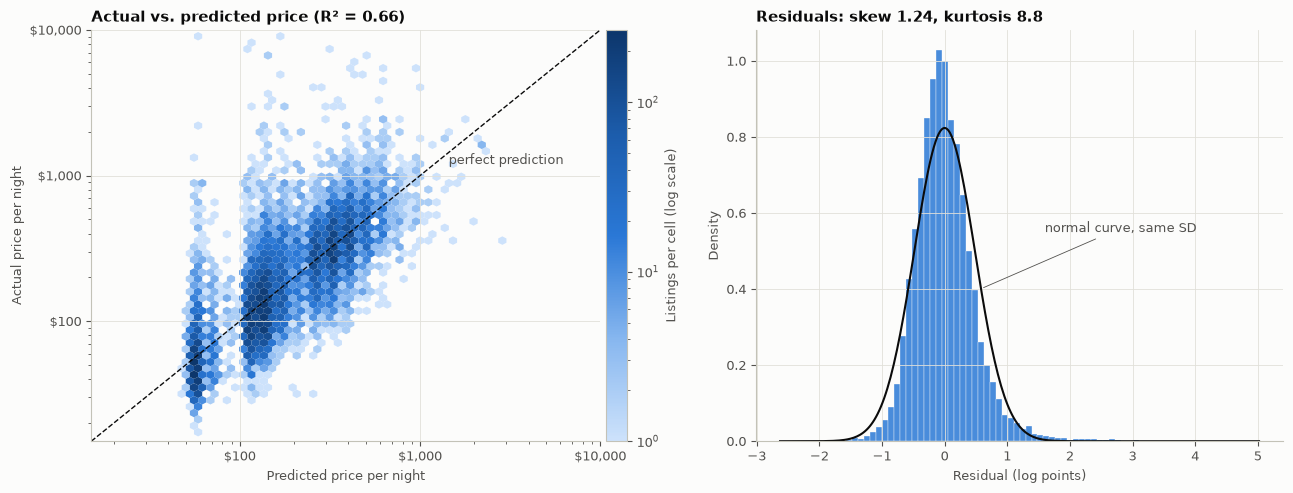

In [6]:
# Model fit: actual vs. predicted nightly price, and the distribution of residuals
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.15, 1]})

pred, act = np.exp(ols.fittedvalues), data["price_num"]
hb = ax1.hexbin(pred, act, xscale="log", yscale="log", gridsize=55, cmap=BLUES, mincnt=1, bins="log", linewidths=0)
lims = [15, 10000]
ax1.plot(lims, lims, color=INK, lw=1, ls="--")
ax1.annotate("perfect prediction", xy=(3000, 3000), xytext=(3000, 1200), color=MUTED, ha="center")
ax1.set_xlim(lims); ax1.set_ylim(lims)
for axis in (ax1.xaxis, ax1.yaxis):
    axis.set_major_formatter(dollar)
ax1.set_xlabel("Predicted price per night"); ax1.set_ylabel("Actual price per night")
ax1.set_title(f"Actual vs. predicted price (R² = {ols.rsquared:.2f})")
fig.colorbar(hb, ax=ax1, label="Listings per cell (log scale)", pad=0.01)

from scipy.stats import norm, skew, kurtosis
r = ols.resid
ax2.hist(r, bins=80, density=True, color=C_BASE, alpha=0.85, edgecolor=SURFACE, linewidth=0.3)
xs = np.linspace(r.min(), r.max(), 300)
ax2.plot(xs, norm.pdf(xs, 0, r.std()), color=INK, lw=1.5)
ax2.annotate("normal curve, same SD", xy=(r.std() * 1.2, norm.pdf(r.std() * 1.2, 0, r.std())),
             xytext=(1.6, 0.55), color=MUTED, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
ax2.set_xlabel("Residual (log points)"); ax2.set_ylabel("Density")
ax2.set_title(f"Residuals: skew {skew(r):.2f}, kurtosis {kurtosis(r, fisher=False):.1f}")
fig.tight_layout(); plt.show()

## Technique 2: Bootstrapping the log-price regression

The OLS standard errors above assume the errors are independent and have constant variance. The residuals here are skewed (skew ≈ 1.2, kurtosis ≈ 8.8), and many hosts run several listings, so their errors are probably correlated. We re-estimate the model on resampled data **B = 1,000** times and use the spread of the estimates instead of the textbook formula.

Two resampling schemes:
1. **Pairs (listing) bootstrap:** draw 16,463 listings with replacement. This is robust to heteroskedasticity.
2. **Host-cluster bootstrap:** draw *hosts* with replacement and keep all of each host's listings together. This is also robust to dependence among listings from the same host.

We report the bootstrap standard errors and 95% percentile confidence intervals (the 2.5th and 97.5th percentiles of the bootstrap estimates).

In [7]:
from patsy import dmatrices

data["host_id"] = df.loc[data.index, "host_id"]

# Build the design matrix once; each bootstrap draw just selects rows
y_mat, X_mat = dmatrices(formula, data, return_type="dataframe")
y_arr, X_arr = y_mat.to_numpy().ravel(), X_mat.to_numpy()
names = results.index.tolist()          # pretty names, intercept excluded
assert np.allclose(np.linalg.lstsq(X_arr, y_arr, rcond=None)[0], ols.params.to_numpy())

def fit_weighted(w):
    # Drawing a row k times is the same as giving it weight k in least squares.
    # Solving the weighted normal equations is much faster than stacking duplicated rows.
    Xw = X_arr * w[:, None]
    return np.linalg.lstsq(Xw.T @ X_arr, Xw.T @ y_arr, rcond=None)[0][1:]   # drop intercept

B = 1000
rng = np.random.default_rng(860)
n = len(y_arr)

# 1) Pairs bootstrap: resample listings
boot_pairs = np.array([fit_weighted(np.bincount(rng.integers(0, n, n), minlength=n)) for _ in range(B)])

# 2) Cluster bootstrap: resample hosts, keep all their listings
host_codes, host_uniques = pd.factorize(data["host_id"])
n_hosts = len(host_uniques)
boot_cluster = np.array([
    fit_weighted(np.bincount(rng.integers(0, n_hosts, n_hosts), minlength=n_hosts)[host_codes])
    for _ in range(B)
])
print(f"{B} replications; {n:,} listings from {n_hosts:,} hosts")

1000 replications; 16,463 listings from 10,939 hosts


In [8]:
def summarize(boot):
    return pd.DataFrame({
        "boot_se": boot.std(axis=0, ddof=1),
        "ci_low": np.percentile(boot, 2.5, axis=0),
        "ci_high": np.percentile(boot, 97.5, axis=0),
    }, index=names)

pairs, cluster = summarize(boot_pairs), summarize(boot_cluster)

comparison = pd.DataFrame({
    "coef": results["coef"],
    "ols_se": results["std_err"],
    "pairs_se": pairs["boot_se"],
    "cluster_se": cluster["boot_se"],
    "cluster_ci_low": cluster["ci_low"],
    "cluster_ci_high": cluster["ci_high"],
})
comparison["se_ratio_cluster/ols"] = comparison["cluster_se"] / comparison["ols_se"]
comparison["significant_5%"] = ~((comparison["cluster_ci_low"] < 0) & (comparison["cluster_ci_high"] > 0))
comparison.round(5)

,coef,ols_se,pairs_se,cluster_se,cluster_ci_low,cluster_ci_high,se_ratio_cluster/ols,significant_5%
room: Hotel room,0.05591,0.06411,0.03835,0.07268,-0.10946,0.16816,1.13362,False
room: Private room,-0.70376,0.00886,0.00937,0.01522,-0.73560,-0.67531,1.71727,True
room: Shared room,-0.80935,0.10115,0.09509,0.09069,-0.96528,-0.61675,0.89657,True
beds,0.20886,0.00359,0.00525,0.00689,0.19544,0.22122,1.92027,True
hosts_time_as_host_years,0.00358,0.00110,0.00108,0.00187,-0.00009,0.00723,1.69858,False
number_of_reviews,-0.00023,0.00006,0.00005,0.00007,-0.00037,-0.00010,1.12669,True
host_is_superhost,-0.05325,0.00815,0.00766,0.01205,-0.07565,-0.02842,1.47886,True
maximum_nights,0.00005,0.00001,0.00001,0.00002,0.00002,0.00009,1.80617,True
monthly_stay,-0.86990,0.00883,0.00884,0.01431,-0.89957,-0.84230,1.62059,True


In [9]:
# Percentile CIs expressed as % change in price, (e^b - 1) * 100
pct = pd.DataFrame({
    "pct_change": results["pct_change_in_price"],
    "pairs_ci": [f"[{(np.exp(l)-1)*100:.2f}%, {(np.exp(h)-1)*100:.2f}%]" for l, h in zip(pairs.ci_low, pairs.ci_high)],
    "cluster_ci": [f"[{(np.exp(l)-1)*100:.2f}%, {(np.exp(h)-1)*100:.2f}%]" for l, h in zip(cluster.ci_low, cluster.ci_high)],
}, index=names)
pct.round(3)

,pct_change,pairs_ci,cluster_ci
room: Hotel room,5.750,"[-1.64%, 14.83%]","[-10.37%, 18.31%]"
room: Private room,-50.528,"[-51.43%, -49.59%]","[-52.08%, -49.10%]"
room: Shared room,-55.485,"[-62.69%, -47.09%]","[-61.91%, -46.03%]"
beds,23.227,"[22.02%, 24.48%]","[21.58%, 24.76%]"
hosts_time_as_host_years,0.359,"[0.14%, 0.57%]","[-0.01%, 0.73%]"
number_of_reviews,-0.023,"[-0.03%, -0.01%]","[-0.04%, -0.01%]"
host_is_superhost,-5.185,"[-6.60%, -3.84%]","[-7.29%, -2.80%]"
maximum_nights,0.005,"[0.00%, 0.01%]","[0.00%, 0.01%]"
monthly_stay,-58.101,"[-58.83%, -57.39%]","[-59.33%, -56.93%]"


### How much the bootstrap changed the uncertainty
Bars to the right of the dashed line mean the textbook OLS formula *understated* the uncertainty. The host-cluster bootstrap, which keeps each host's listings together, gives standard errors about 1.5–2× the OLS ones for most variables. It is the version used for all significance calls.

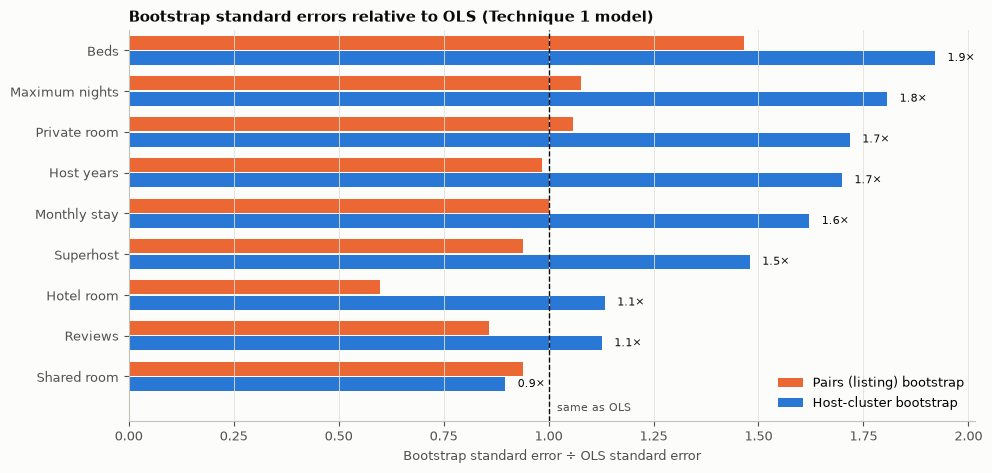

In [10]:
# How much did the bootstrap change the standard errors? (ratio to the textbook OLS standard error)
se = comparison[["ols_se", "pairs_se", "cluster_se"]].copy()
se["pairs_ratio"], se["cluster_ratio"] = se["pairs_se"] / se["ols_se"], se["cluster_se"] / se["ols_se"]
se = se.sort_values("cluster_ratio")
pretty = {"beds": "Beds", "maximum_nights": "Maximum nights", "hosts_time_as_host_years": "Host years",
          "monthly_stay": "Monthly stay", "host_is_superhost": "Superhost", "number_of_reviews": "Reviews"}
se.index = [pretty.get(i, i.replace("room: ", "")) for i in se.index]

fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(se)); h = 0.38
ax.barh(y + h / 2, se["pairs_ratio"], height=h - 0.04, color=C_FLAG, label="Pairs (listing) bootstrap")
ax.barh(y - h / 2, se["cluster_ratio"], height=h - 0.04, color=C_BASE, label="Host-cluster bootstrap")
for yi, v in zip(y, se["cluster_ratio"]):
    ax.text(v + 0.03, yi - h / 2, f"{v:.1f}×", va="center", color=INK, fontsize=8)
ax.axvline(1, color=INK, lw=1, ls="--")
ax.text(1.02, -0.85, "same as OLS", color=MUTED, fontsize=8)
ax.set_ylim(-1.1, len(se) - 0.5)
ax.set_yticks(y, se.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("Bootstrap standard error ÷ OLS standard error")
ax.set_title("Bootstrap standard errors relative to OLS (Technique 1 model)")
ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

## Technique 3: Neighbourhood differences and a fixed-effects regression

### 3a. Rank neighbourhoods by average nightly price
We use the same 16,463-listing estimation sample as the models above.

In [11]:
data["neighbourhood"] = df.loc[data.index, "neighbourhood_cleansed"]

nbhd = (data.groupby("neighbourhood")["price_num"]
        .agg(n="size", mean_price="mean", median_price="median", sd="std")
        .sort_values("mean_price"))
print(f"{len(nbhd)} neighbourhoods")
pd.concat([nbhd.head(5), nbhd.tail(5)]).round(2)

140 neighbourhoods


,n,mean_price,median_price,sd
neighbourhood,,,,
York University Heights,177,74.37,41.67,69.91
Mount Olive-Silverstone-Jamestown,17,86.89,62.56,50.78
Steeles,56,92.57,86.00,53.43
Don Valley Village,113,93.83,77.92,64.30
L'Amoreaux,108,95.55,57.90,86.82
Lawrence Park South,54,391.12,164.92,846.75
Princess-Rosethorn,34,397.57,85.34,1323.90
Forest Hill South,30,399.49,225.23,453.26
Scarborough Village,17,600.93,105.00,1793.41


### 3b. Hypothesis test: most expensive vs. cheapest neighbourhood

- $H_0: \mu_{\text{highest}} = \mu_{\text{lowest}}$
- $H_1: \mu_{\text{highest}} \neq \mu_{\text{lowest}}$
- $\alpha = 0.05$

We use Welch's two-sample t-test, which does not assume the two neighbourhoods have equal variances. Prices are heavily right-skewed, so we also run the test on log price as a robustness check.

In [12]:
from scipy import stats

low_name, high_name = nbhd.index[0], nbhd.index[-1]
low = data.loc[data["neighbourhood"] == low_name]
high = data.loc[data["neighbourhood"] == high_name]

alpha = 0.05
rows = []
for label, col in [("price ($)", "price_num"), ("ln(price)", "ln_price")]:
    t, p = stats.ttest_ind(high[col], low[col], equal_var=False)
    rows.append({"variable": label,
                 f"mean {high_name} (n={len(high)})": high[col].mean(),
                 f"mean {low_name} (n={len(low)})": low[col].mean(),
                 "t_stat": t, "p_value": p,
                 "decision": "Reject H0" if p < alpha else "Fail to reject H0"})
pd.DataFrame(rows).set_index("variable").round(4)

,mean Bridle Path-Sunnybrook-York Mills (n=21),mean York University Heights (n=177),t_stat,p_value,decision
variable,,,,,
price ($),614.2033,74.3712,2.2337,0.0371,Reject H0
ln(price),5.4674,4.0369,5.1221,0.0000,Reject H0


Comparing only the two extremes is a narrow test. The extremes can come from small neighbourhoods with only a few listings, and picking the two most extreme groups after looking at the data favours finding a difference. As a broader check, we also run a one-way ANOVA (plus the rank-based Kruskal–Wallis test) of $H_0$: all neighbourhood mean log prices are equal.

In [13]:
groups = [g["ln_price"].to_numpy() for _, g in data.groupby("neighbourhood")]
f_stat, p_anova = stats.f_oneway(*groups)
h_stat, p_kw = stats.kruskal(*groups)
print(f"One-way ANOVA (ln price):  F = {f_stat:.2f}, p = {p_anova:.3g}")
print(f"Kruskal-Wallis (ln price): H = {h_stat:.2f}, p = {p_kw:.3g}")

One-way ANOVA (ln price):  F = 31.27, p = 0
Kruskal-Wallis (ln price): H = 3575.04, p = 0


### 3c. Re-estimate the model with neighbourhood fixed effects

$$\ln(\text{Price})_i = \beta_0 + \beta_1\,\#\text{beds}_i + \dots + \beta_7\,\text{Monthly stay}_i + \alpha_{\text{neighbourhood}(i)} + \varepsilon_i$$

$\alpha_{\text{neighbourhood}}$ gives each neighbourhood its own intercept. The other coefficients are then estimated only from price differences between listings in the same neighbourhood. This removes bias from location factors that are correlated with the regressors (e.g. downtown listings have fewer beds and higher prices).

In [14]:
formula_fe = formula + " + C(neighbourhood)"
ols_fe = smf.ols(formula_fe, data=data).fit()

# Joint F-test: are all neighbourhood effects zero?
f_test = ols_fe.compare_f_test(ols)
print(f"R-squared: pooled = {ols.rsquared:.3f}, fixed effects = {ols_fe.rsquared:.3f}")
print(f"Joint F-test of neighbourhood effects: F = {f_test[0]:.2f}, p = {f_test[1]:.3g}, df = {int(f_test[2])}")

R-squared: pooled = 0.661, fixed effects = 0.713
Joint F-test of neighbourhood effects: F = 21.49, p = 0, df = 139


### 3d. Bootstrap the fixed-effects model (host-cluster, B = 1,000)
Following Technique 2, we resample hosts with replacement and keep all of each host's listings together.

In [15]:
def cluster_bootstrap(formula, data, B=1000, seed=860):
    y_m, X_m = dmatrices(formula, data, return_type="dataframe")
    y, X = y_m.to_numpy().ravel(), X_m.to_numpy()
    codes, uniq = pd.factorize(data["host_id"])
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(B):
        # weight = number of times each listing's host was drawn
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes]
        Xw = X * w[:, None]
        draws.append(np.linalg.lstsq(Xw.T @ X, Xw.T @ y, rcond=None)[0])
    return pd.DataFrame(draws, columns=X_m.columns)

boot_fe = cluster_bootstrap(formula_fe, data)

core = [c for c in ols.params.index if c != "Intercept"]     # the 9 main regressors
fe_table = pd.DataFrame({
    "pooled_coef": ols.params[core],
    "pooled_cluster_se": cluster["boot_se"].to_numpy(),
    "fe_coef": ols_fe.params[core],
    "fe_cluster_se": boot_fe[core].std(ddof=1),
    "fe_ci_low": boot_fe[core].quantile(0.025),
    "fe_ci_high": boot_fe[core].quantile(0.975),
})
fe_table["fe_pct_change"] = (np.exp(fe_table["fe_coef"]) - 1) * 100
fe_table["change_vs_pooled_%"] = (fe_table["fe_coef"] / fe_table["pooled_coef"] - 1) * 100
fe_table["significant_5%"] = ~((fe_table["fe_ci_low"] < 0) & (fe_table["fe_ci_high"] > 0))
fe_table.index = names
fe_table.round(5)

,pooled_coef,pooled_cluster_se,fe_coef,fe_cluster_se,fe_ci_low,fe_ci_high,fe_pct_change,change_vs_pooled_%,significant_5%
room: Hotel room,0.05591,0.07268,0.04960,0.05287,-0.05276,0.15392,5.08459,-11.29263,False
room: Private room,-0.70376,0.01522,-0.52212,0.01630,-0.55116,-0.48751,-40.67385,-25.81014,True
room: Shared room,-0.80935,0.09069,-0.73430,0.10714,-0.92604,-0.51115,-52.01603,-9.27249,True
beds,0.20886,0.00689,0.22453,0.00674,0.21188,0.23724,25.17348,7.50473,True
hosts_time_as_host_years,0.00358,0.00187,0.00418,0.00167,0.00084,0.00759,0.41856,16.52352,True
number_of_reviews,-0.00023,0.00007,-0.00043,0.00006,-0.00055,-0.00030,-0.04255,83.31971,True
host_is_superhost,-0.05325,0.01205,-0.05667,0.01065,-0.07852,-0.03670,-5.50943,6.42718,True
maximum_nights,0.00005,0.00002,0.00005,0.00001,0.00003,0.00008,0.00545,4.19665,True
monthly_stay,-0.86990,0.01431,-0.84049,0.01264,-0.86499,-0.81553,-56.85029,-3.38014,True


In [16]:
# Neighbourhood premiums relative to the baseline neighbourhood (largest and smallest 5)
nb_cols = [c for c in ols_fe.params.index if c.startswith("C(neighbourhood)")]
baseline = sorted(data["neighbourhood"].unique())[0]
nb_eff = pd.DataFrame({
    "coef": ols_fe.params[nb_cols],
    "pct_vs_baseline": (np.exp(ols_fe.params[nb_cols]) - 1) * 100,
    "ci_low": boot_fe[nb_cols].quantile(0.025),
    "ci_high": boot_fe[nb_cols].quantile(0.975),
}).sort_values("coef")
nb_eff.index = nb_eff.index.str.extract(r"\[T\.(.*)\]")[0].to_numpy()
print(f"Baseline neighbourhood: {baseline}")
pd.concat([nb_eff.head(5), nb_eff.tail(5)]).round(3)

Baseline neighbourhood: Agincourt North


,coef,pct_vs_baseline,ci_low,ci_high
York University Heights,-0.130,-12.213,-0.316,0.122
Ionview,-0.125,-11.768,-0.344,0.119
Kennedy Park,-0.117,-11.018,-0.343,0.149
Thistletown-Beaumond Heights,-0.113,-10.698,-0.312,0.112
Malvern,-0.111,-10.522,-0.317,0.108
Niagara,0.554,74.062,0.384,0.724
Rosedale-Moore Park,0.571,77.002,0.372,0.793
Annex,0.576,77.804,0.405,0.755
Waterfront Communities-The Island,0.576,77.874,0.414,0.749
Bay Street Corridor,0.592,80.825,0.410,0.769


### Model performance: pooled vs. fixed effects
To check for overfitting, each model is re-fitted on 80% of hosts and scored on the other 20%, five times. Hosts are kept whole in one fold, so a host's pricing style can't leak from training into testing. If the out-of-sample R² is close to the in-sample R², the model isn't just memorizing the data. The RMSE is in log points, so $e^{\text{RMSE}}-1$ is the typical % error of a single prediction. The right panel shows which effects change once neighbourhood is held constant. The private-room discount shrinks the most, because private rooms are concentrated in cheaper neighbourhoods.

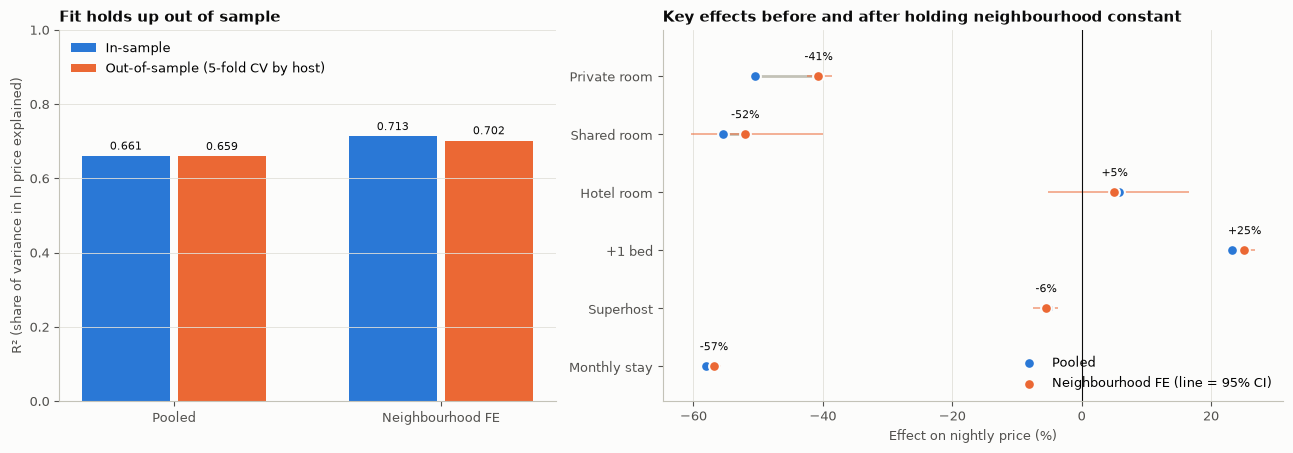

,in_sample_R2,in_sample_RMSE,cv_R2,cv_RMSE,cv_typical_error_%
Pooled (Technique 1),0.661,0.484,0.659,0.485,62.411
Neighbourhood FE (Technique 3),0.713,0.447,0.702,0.454,57.426


In [17]:
# Out-of-sample performance: 5-fold cross-validation, splitting by HOST so that a host's listings
# are never in both the training and the test fold (otherwise shared host traits would leak).
def cv_scores(formula, data, k=5, seed=860):
    y_m, X_m = dmatrices(formula, data, return_type="dataframe")
    y, X = y_m.to_numpy().ravel(), X_m.to_numpy()
    codes, uniq = pd.factorize(data["host_id"])
    fold_of_host = np.random.default_rng(seed).integers(0, k, len(uniq))
    fold = fold_of_host[codes]
    pred = np.empty_like(y)
    for f in range(k):
        tr, te = fold != f, fold == f
        beta = np.linalg.lstsq(X[tr], y[tr], rcond=None)[0]   # a neighbourhood unseen in training gets 0
        pred[te] = X[te] @ beta
    rmse = np.sqrt(np.mean((y - pred) ** 2))
    r2 = 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)
    return r2, rmse

perf = pd.DataFrame({
    "in_sample_R2": [ols.rsquared, ols_fe.rsquared],
    "in_sample_RMSE": [np.sqrt(ols.mse_resid), np.sqrt(ols_fe.mse_resid)],
}, index=["Pooled (Technique 1)", "Neighbourhood FE (Technique 3)"])
perf[["cv_R2", "cv_RMSE"]] = [cv_scores(formula, data), cv_scores(formula_fe, data)]
# RMSE is in log points; exp(RMSE) - 1 is the typical % prediction error
perf["cv_typical_error_%"] = (np.exp(perf["cv_RMSE"]) - 1) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})

# Panel 1: R² in-sample vs out-of-sample
x = np.arange(len(perf)); w = 0.36
b1 = ax1.bar(x - w / 2, perf["in_sample_R2"], w - 0.03, color=C_BASE, label="In-sample")
b2 = ax1.bar(x + w / 2, perf["cv_R2"], w - 0.03, color=C_FLAG, label="Out-of-sample (5-fold CV by host)")
for bars in (b1, b2):
    for b in bars:
        ax1.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.3f}",
                 ha="center", va="bottom", color=INK, fontsize=8)
ax1.set_xticks(x, ["Pooled", "Neighbourhood FE"]); ax1.grid(axis="x", visible=False)
ax1.set_ylim(0, 1); ax1.set_ylabel("R² (share of variance in ln price explained)")
ax1.set_title("Fit holds up out of sample")
ax1.legend(loc="upper left")

# Panel 2: how the key effects change once location is held constant (with FE bootstrap 95% CI)
keep = ["room: Private room", "room: Shared room", "room: Hotel room", "beds", "host_is_superhost", "monthly_stay"]
labels = ["Private room", "Shared room", "Hotel room", "+1 bed", "Superhost", "Monthly stay"]
ft = fe_table.loc[keep]
pooled_pct = (np.exp(ft["pooled_coef"]) - 1) * 100
fe_pct = (np.exp(ft["fe_coef"]) - 1) * 100
fe_lo, fe_hi = (np.exp(ft["fe_ci_low"]) - 1) * 100, (np.exp(ft["fe_ci_high"]) - 1) * 100
yy = np.arange(len(keep))[::-1]
for yi, a, b in zip(yy, pooled_pct, fe_pct):
    ax2.plot([a, b], [yi, yi], color="#c3c2b7", lw=2, zorder=1)
ax2.hlines(yy, fe_lo, fe_hi, color=C_FLAG, lw=1.2, alpha=0.6, zorder=2)
ax2.scatter(pooled_pct, yy, s=60, color=C_BASE, edgecolors=SURFACE, linewidths=1.5, zorder=3, label="Pooled")
ax2.scatter(fe_pct, yy, s=60, color=C_FLAG, edgecolors=SURFACE, linewidths=1.5, zorder=3,
            label="Neighbourhood FE (line = 95% CI)")
for yi, v in zip(yy, fe_pct):
    ax2.text(v, yi + 0.28, f"{v:+.0f}%", ha="center", color=INK, fontsize=8)
ax2.axvline(0, color=INK, lw=0.8)
ax2.set_yticks(yy, labels); ax2.grid(axis="y", visible=False)
ax2.set_ylim(-0.6, len(keep) - 0.2)   # room for the value labels above the top row
ax2.set_xlabel("Effect on nightly price (%)")
ax2.set_title("Key effects before and after holding neighbourhood constant")
ax2.legend(loc="lower right")
fig.tight_layout(); plt.show()
perf.round(3)

## Technique 4: Identifying outliers

We plot every listing's price against each feature, then measure how unusual each listing is in two ways:

| Measure | What it captures | Flag rule |
|---|---|---|
| **Leverage** $h_{ii}$ | How far a listing's *features* sit from the crowd (e.g. 20 beds, a shared room) | $h_{ii} > 3p/n$ |
| **Studentized residual** | How far its *price* is from what the model predicts | $\lvert r_i\rvert > 3$ |
| **Cook's distance** | How much the coefficients move when that one listing is dropped (leverage × residual) | $D_i > 4/n$ |

Leverage is computed from the listing features (the pooled design in Technique 1). Under the fixed-effects model, every listing in a small neighbourhood gets high leverage automatically, so that leverage would mostly flag small neighbourhoods. Residuals and Cook's distance come from the fixed-effects model (Technique 3), our preferred specification.

In [18]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

def influence(res):
    # Leverage, externally studentized residuals and Cook's distance from the textbook formulas.
    # (statsmodels' get_influence() is very slow with ~150 fixed-effect columns.)
    X = res.model.exog
    h = np.einsum("ij,ij->i", X @ np.linalg.pinv(X.T @ X), X)     # diagonal of the hat matrix
    e, n, p = res.resid.to_numpy(), int(res.nobs), int(res.df_model) + 1
    s2 = res.ssr / (n - p)
    s2_loo = (res.ssr - e**2 / (1 - h)) / (n - p - 1)               # error variance without obs i
    stud_ext = e / np.sqrt(s2_loo * (1 - h))
    cooks = (e**2 / (p * s2)) * h / (1 - h) ** 2
    return h, stud_ext, cooks

lev_pooled, _, _ = influence(ols)
_, stud_fe, cooks_fe = influence(ols_fe)

n_obs, p_pooled = int(ols.nobs), int(ols.df_model) + 1
data["leverage"] = lev_pooled
data["stud_resid"] = stud_fe
data["cooks_d"] = cooks_fe
data["fitted_fe"] = ols_fe.fittedvalues

lev_cut, cook_cut = 3 * p_pooled / n_obs, 4 / n_obs
data["high_leverage"] = data["leverage"] > lev_cut
data["large_resid"] = data["stud_resid"].abs() > 3
data["influential"] = data["cooks_d"] > cook_cut

print(f"Leverage cutoff 3p/n = {lev_cut:.4f};  Cook's D cutoff 4/n = {cook_cut:.6f}")
data[["high_leverage", "large_resid", "influential"]].agg(["sum", "mean"]).T.rename(
    columns={"sum": "listings_flagged", "mean": "share"}).round(4)

Leverage cutoff 3p/n = 0.0018;  Cook's D cutoff 4/n = 0.000243


,listings_flagged,share
high_leverage,273.0,0.0166
large_resid,215.0,0.0131
influential,793.0,0.0482


### Scatter plots: price against each feature
Each dot is a listing; listings flagged for high leverage are highlighted. Price is on a log scale, the same scale the model uses.

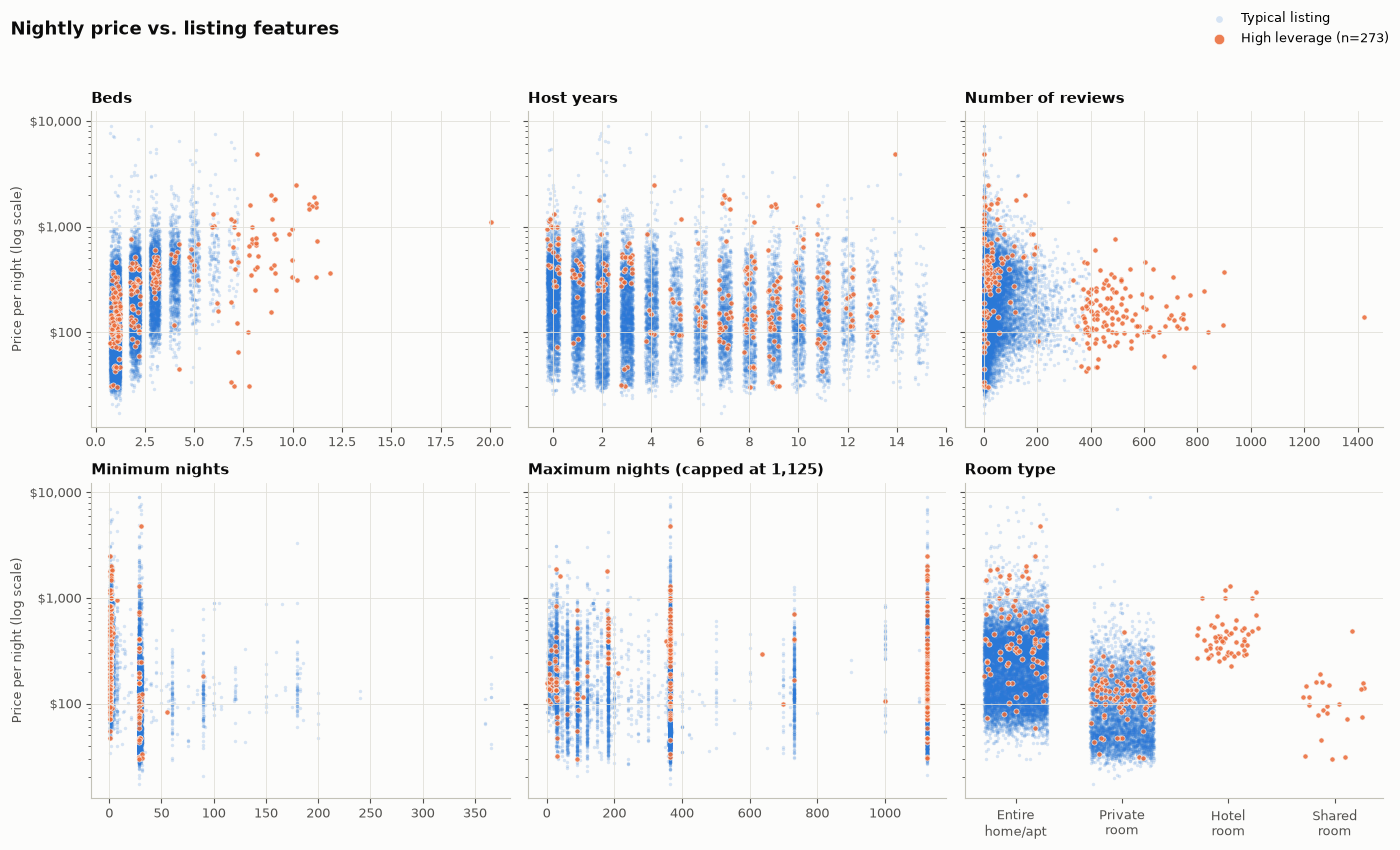

In [19]:
rng_plot = np.random.default_rng(0)
room_order = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]

panels = [("beds", "Beds"), ("hosts_time_as_host_years", "Host years"),
          ("number_of_reviews", "Number of reviews"), ("minimum_nights", "Minimum nights"),
          ("maximum_nights", "Maximum nights (capped at 1,125)"), ("room_type", "Room type")]

fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), sharey=True)
for ax, (col, label) in zip(axes.ravel(), panels):
    if col == "room_type":
        x = data["room_type"].map({r: i for i, r in enumerate(room_order)}) + rng_plot.uniform(-0.3, 0.3, len(data))
        ax.set_xticks(range(4), [r.replace(" ", "\n", 1) for r in room_order])
        ax.grid(axis="x", visible=False)
    else:
        jitter = 0.25 if col in ("beds", "hosts_time_as_host_years") else 0
        x = data[col] + rng_plot.uniform(-jitter, jitter, len(data))
    flag = data["high_leverage"]
    ax.scatter(x[~flag], data.loc[~flag, "price_num"], s=6, c=C_BASE, alpha=0.18, linewidths=0, label="Typical listing")
    ax.scatter(x[flag], data.loc[flag, "price_num"], s=14, c=C_FLAG, alpha=0.85,
               edgecolors=SURFACE, linewidths=0.5, label=f"High leverage (n={flag.sum()})")
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(dollar)
    ax.set_title(label)
for ax in axes[:, 0]:
    ax.set_ylabel("Price per night (log scale)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", frameon=False, markerscale=2)
fig.suptitle("Nightly price vs. listing features", x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### Residuals vs. fitted values (heteroskedasticity check)
If the error variance were constant, this would be an even horizontal band. A funnel shape or a dense cluster at one end means heteroskedasticity, which is why Technique 2 uses bootstrapped standard errors.

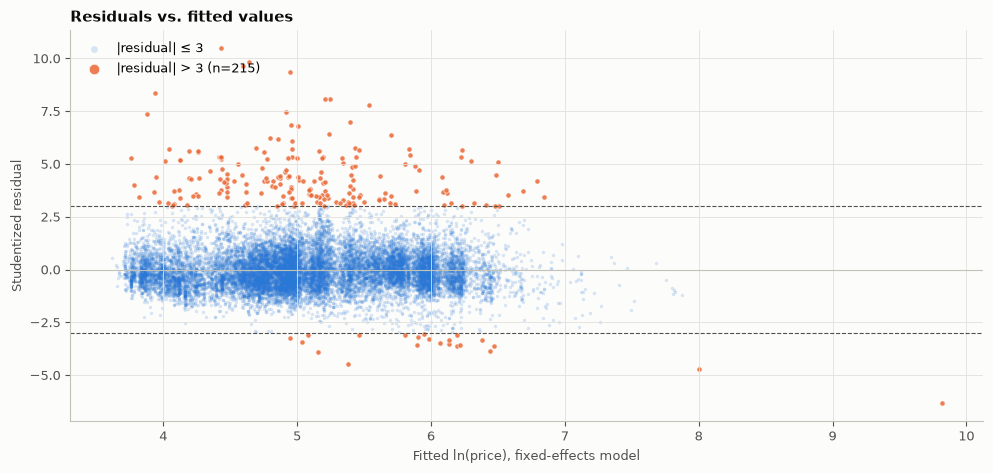

fitted_fe
0    0.854
1    1.135
2    0.924
3    0.961
4    1.042
5    1.091
6    1.138
7    0.820
8    0.881
9    1.055


In [20]:
fig, ax = plt.subplots(figsize=(10, 4.8))
big = data["large_resid"]
ax.scatter(data.loc[~big, "fitted_fe"], data.loc[~big, "stud_resid"], s=6, c=C_BASE, alpha=0.18, linewidths=0, label="|residual| ≤ 3")
ax.scatter(data.loc[big, "fitted_fe"], data.loc[big, "stud_resid"], s=14, c=C_FLAG, alpha=0.85,
           edgecolors=SURFACE, linewidths=0.5, label=f"|residual| > 3 (n={big.sum()})")
for yv in (-3, 3):
    ax.axhline(yv, color=MUTED, lw=0.8, ls="--")
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_xlabel("Fitted ln(price), fixed-effects model"); ax.set_ylabel("Studentized residual")
ax.set_title("Residuals vs. fitted values")
ax.legend(frameon=False, loc="upper left", markerscale=2)
fig.tight_layout(); plt.show()

# Spread of residuals by fitted-value decile (constant variance -> roughly equal SDs)
print(data.groupby(pd.qcut(data["fitted_fe"], 10, labels=False))["stud_resid"].std().round(3).rename("resid_sd_by_fitted_decile").to_string())

### Who gets flagged, and why?
For each high-leverage listing we record which feature makes it unusual.

In [21]:
extra = df.loc[data.index, ["listing_url", "property_type", "accommodates", "bedrooms"]]
for c in extra.columns:
    data[c] = extra[c]

hl = data[data["high_leverage"]]
reasons = pd.DataFrame({
    "Hotel or shared room (rare category)": hl["room_type"].isin(["Hotel room", "Shared room"]),
    "Beds ≥ 6": hl["beds"] >= 6,
    "Reviews ≥ 300": hl["number_of_reviews"] >= 300,
})
reasons["None of the above"] = ~reasons.any(axis=1)
print(f"{len(hl)} high-leverage listings (a listing can have several reasons):")
reasons.sum().rename("listings").to_frame()

273 high-leverage listings (a listing can have several reasons):


,listings
Hotel or shared room (rare category),81
Beds ≥ 6,62
Reviews ≥ 300,138
None of the above,0


### Typo or real-but-unusual?
We can't confirm each listing by hand, so we apply plausibility rules to the flagged listings (high leverage, large residual or influential). A listing is a **suspected data error** if:
- its price per guest is above $1,000 a night (e.g. $9,044 for a one-bed, two-guest hotel room), **or**
- it has more beds than 2 × the number of guests it accommodates, **or**
- it is an entire home with ≥ 2 beds priced under $35 a night.

Everything else that is flagged (hotel rooms, large homes, long-stay rentals, heavily reviewed listings) is treated as **real but unusual**. The URLs are printed so the suspected errors can be checked by hand.

In [22]:
data["any_flag"] = data["high_leverage"] | data["large_resid"] | data["influential"]
data["price_per_guest"] = data["price_num"] / data["accommodates"]

data["suspect_error"] = data["any_flag"] & (
    (data["price_per_guest"] > 1000)
    | (data["beds"] > 2 * data["accommodates"])
    | ((data["room_type"] == "Entire home/apt") & (data["beds"] >= 2) & (data["price_num"] < 35))
)
print(f"Flagged by any measure: {data['any_flag'].sum():,}   Suspected data errors: {data['suspect_error'].sum()}")
(data.loc[data["suspect_error"], ["listing_url", "property_type", "accommodates", "beds",
                                  "price_num", "price_per_guest", "stud_resid", "cooks_d"]]
     .sort_values("price_per_guest", ascending=False).round(3))

Flagged by any measure: 1,104   Suspected data errors: 21


,listing_url,property_type,accommodates,beds,price_num,price_per_guest,stud_resid,cooks_d
13945,https://www.airbnb.com/rooms/36472537,Room in boutique hotel,2,1.0,9044.00,4522.000,10.508,0.002
1817,https://www.airbnb.com/rooms/1079650206184425990,Entire home,2,1.0,7752.00,3876.000,9.824,0.020
4257,https://www.airbnb.com/rooms/1079656657699541492,Entire home,2,1.0,7235.20,3617.600,9.663,0.005
369,https://www.airbnb.com/rooms/42037807,Room in boutique hotel,2,1.0,7000.00,3500.000,8.099,0.001
1991,https://www.airbnb.com/rooms/53748226,Private room in condo,1,1.0,2113.06,2113.060,8.384,0.006
13265,https://www.airbnb.com/rooms/1593512084257064581,Entire home,4,2.0,6742.40,1685.600,8.084,0.001
11928,https://www.airbnb.com/rooms/1192042581476652580,Entire rental unit,6,3.0,9049.10,1508.183,9.372,0.005
1987,https://www.airbnb.com/rooms/1075395898601876491,Private room in home,1,1.0,1266.16,1266.160,7.385,0.007
3187,https://www.airbnb.com/rooms/15286188,Entire condo,3,2.0,3319.48,1106.493,6.419,0.000
15853,https://www.airbnb.com/rooms/952939258822240087,Private room in home,2,1.0,2010.00,1005.000,6.188,0.004


### Does removing them change the results?
We re-estimate the fixed-effects model on four samples and bootstrap each one (host-cluster, B = 1,000):
1. **Full sample:** the Technique 3 model.
2. **Drop suspected errors:** our preferred cleaned sample.
3. **Drop all high-leverage listings.**
4. **Drop all influential listings** (Cook's D > 4/n).

Samples 3 and 4 are stress tests. Dropping listings only because they are unusual throws away real information, e.g. removing every hotel and shared room.

In [23]:
samples = {
    "full": data,
    "drop_suspect_errors": data[~data["suspect_error"]],
    "drop_high_leverage": data[~data["high_leverage"]],
    "drop_influential": data[~data["influential"]],
}
pct_rows, sig_rows, n_rows = {}, {}, {}
for name, d in samples.items():
    boot = boot_fe if name == "full" else cluster_bootstrap(formula_fe, d)
    fit_s = ols_fe if name == "full" else smf.ols(formula_fe, data=d).fit()
    coefs = fit_s.params.reindex(core)          # NaN if a category was dropped entirely
    lo, hi = boot.reindex(columns=core).quantile(0.025), boot.reindex(columns=core).quantile(0.975)
    pct_rows[name] = (np.exp(coefs) - 1) * 100
    sig_rows[name] = np.where(coefs.isna(), "dropped", np.where((lo > 0) | (hi < 0), "yes", "no"))
    n_rows[name] = len(d)

robust_pct = pd.DataFrame(pct_rows); robust_pct.index = names
robust_sig = pd.DataFrame(sig_rows, index=names)
print("Observations:", n_rows)
print("\n% change in price per unit (fixed-effects model):")
print(robust_pct.round(3).to_string())
print("\nSignificant at 5% (bootstrap 95% CI excludes 0):")
print(robust_sig.to_string())

Observations: {'full': 16463, 'drop_suspect_errors': 16442, 'drop_high_leverage': 16190, 'drop_influential': 15670}

% change in price per unit (fixed-effects model):
                            full  drop_suspect_errors  drop_high_leverage  drop_influential
room: Hotel room           5.085                4.502                 NaN             2.307
room: Private room       -40.674              -40.569             -39.920           -40.696
room: Shared room        -52.016              -50.342                 NaN           -51.753
beds                      25.173               25.454              27.358            25.032
hosts_time_as_host_years   0.419                0.456               0.528             0.581
number_of_reviews         -0.043               -0.043              -0.065            -0.041
host_is_superhost         -5.509               -5.277              -5.227            -3.802
maximum_nights             0.005                0.005               0.006             0.004
month

### Technique 4 findings
- **The monthly-stay variable fixed a specification problem.** With minimum nights as a straight-line term, rentals with a 360–365-night minimum were predicted at about $2–4 a night and formed a cluster of large residuals at fitted ln(price) ≈ 0–1. The model now treats minimum stay as a yes/no variable (Technique 1) and that cluster is gone. R² rose from 0.54 to 0.66 (pooled) and from 0.61 to 0.71 (fixed effects).
- **Fixing it changed several other coefficients.** Short-term listings (under 28 nights) have more superhosts (53% vs. 31%) and more reviews (57 vs. 19 on average), and their hosts are newer (3.0 vs. 5.4 years). The straight-line term didn't fully capture the short-term premium, so superhost, reviews and host years were partly picking it up. With the yes/no variable, superhost (−5.5%) and reviews (−0.04% each) turn negative, host years turns slightly positive, and the hotel-room premium is no longer significant.
- **Most flagged listings are real but unusual, not errors.** The 273 high-leverage listings are hotel or shared rooms, homes with 6+ beds, or listings with 300+ reviews. Only 21 of the 1,104 listings flagged by any measure look like data errors: one-bed rooms priced at $7,000–$9,000 a night, and private rooms for 1 guest that list 3–7 beds.
- **Removing outliers no longer changes any conclusion.** In all three trimmed samples (suspected errors, high leverage, influential), every coefficient keeps its sign and its significance call. Dropping high-leverage listings still removes every hotel and shared room, so we keep the cleaned sample (suspected errors dropped) as the preferred one.
- **Heteroskedasticity remains:** the residual spread by fitted-value decile ranges from SD 0.82 to 1.14, so bootstrapped standard errors are still needed.

## Technique 5: Effect of price on booking (control-function logit)

Price and bookings are decided together. A host who sees strong demand raises the price, so a plain logit of *booked* on price mixes the price effect with demand the model can't see. That makes price **endogenous**: it is correlated with the error term in the booking equation. The control-function approach handles this in two stages:

1. **Stage 1 (OLS):** $\ln(\text{price})_i = \pi\, Z_i + \text{controls}_i + \alpha_{\text{nbhd}(i)} + v_i$
2. **Stage 2 (logit):** $\Pr(\text{booked}_i = 1) = \Lambda\big(\beta \ln(\text{price})_i + \rho\, \hat v_i + \text{controls}_i + \alpha_{\text{nbhd}(i)}\big)$

Including the first-stage residual $\hat v_i$ picks up the part of price driven by demand the model can't see, so $\beta$ measures the effect of price itself. A significant $\rho$ is evidence that price really is endogenous.

**Outcome: booked.** The data has no booking records, so we use a proxy: *booked = 1 if the listing received at least one review in the last 30 days*, meaning a guest stayed recently. That window matches the current listed price. It undercounts bookings, because not every guest leaves a review.

**Instrument $Z_i$:** the host's average *price premium* on their listings in **other** neighbourhoods. A listing's premium is its residual from the Technique 3 fixed-effects model, i.e. how much more it charges than a comparable listing in the same neighbourhood. Some hosts price high everywhere, so this predicts the listing's own price (relevance). Because it comes from other neighbourhoods, it shouldn't reflect demand shocks in this listing's neighbourhood (exclusion). It only exists for hosts with listings in two or more neighbourhoods.

**Controls (both stages):** beds, room type, host years, superhost, maximum nights, monthly stay and neighbourhood fixed effects. Total reviews is left out because the outcome is defined by reviews.

**Standard errors:** both stages are re-estimated together on 1,000 host-level bootstrap resamples, so the uncertainty from estimating $\hat v$ in stage 1 carries into stage 2.

In [24]:
# --- Booking outcome and extra listing info from the raw file (not kept in listings_clean.csv) ---
raw = pd.read_csv("listings.csv", usecols=["id", "number_of_reviews_l30d", "number_of_reviews_ltm", "availability_30"])
raw = raw.set_index("id")
ids = df.loc[data.index, "id"]
data["reviews_l30d"] = raw.loc[ids, "number_of_reviews_l30d"].to_numpy()
# booked = 1 if the listing got at least one review in the last 30 days (a guest stayed recently)
data["booked"] = (data["reviews_l30d"] > 0).astype(int)

# --- Instrument: the host's average price premium on their listings in OTHER neighbourhoods ---
# A listing's "price premium" is its residual from the Technique 3 fixed-effects model: how much more
# (in log points) it charges than an otherwise identical listing in the same neighbourhood.
data["premium"] = ols_fe.resid

# For listing i of host h in neighbourhood n: average premium over h's listings outside n.
# Computed as (host total - host total in n) / (host count - host count in n).
g_host = data.groupby("host_id")["premium"]
g_host_nb = data.groupby(["host_id", "neighbourhood"])["premium"]
sum_other = g_host.transform("sum") - g_host_nb.transform("sum")
cnt_other = g_host.transform("size") - g_host_nb.transform("size")
data["host_premium_other_nbhd"] = np.where(cnt_other > 0, sum_other / cnt_other.where(cnt_other > 0), np.nan)

iv = data[data["host_premium_other_nbhd"].notna()].copy()
print(f"Listings whose host also lists in another neighbourhood: {len(iv):,} "
      f"from {iv['host_id'].nunique():,} hosts, in {iv['neighbourhood'].nunique()} neighbourhoods")
print(f"Share booked (review in last 30 days): full sample {data['booked'].mean():.3f}, IV sample {iv['booked'].mean():.3f}")

Listings whose host also lists in another neighbourhood: 3,346 from 590 hosts, in 134 neighbourhoods
Share booked (review in last 30 days): full sample 0.444, IV sample 0.246


### Stage 1: is the instrument relevant?
A first-stage F-statistic above 10 is the usual threshold for a strong instrument. Standard errors are clustered by host, because the instrument is shared across a host's listings.

In [25]:
# Controls used in both stages. number_of_reviews is left out because the outcome (booked) is defined by reviews.
controls = ("beds + C(room_type, Treatment('Entire home/apt')) + hosts_time_as_host_years "
            "+ host_is_superhost + maximum_nights + monthly_stay + C(neighbourhood)")

# A neighbourhood or room type where every listing is booked (or none is) gives no information in a logit,
# and its coefficient diverges to +/- infinity (e.g. all 4 shared rooms in this sample are booked).
# Drop such groups before both stages (as Stata's logit does) so stage 1 and stage 2 use the same listings.
# Repeat until stable, because dropping one group can leave another with no variation.
iv2 = iv.copy()
while True:
    keep = np.ones(len(iv2), dtype=bool)
    for col in ["neighbourhood", "room_type"]:
        keep &= iv2.groupby(col)["booked"].transform("nunique").to_numpy() > 1
    if keep.all():
        break
    iv2 = iv2[keep].copy()
print(f"Estimation sample: {len(iv2):,} listings from {iv2['host_id'].nunique()} hosts "
      f"({len(iv) - len(iv2)} dropped from neighbourhoods/room types with no variation in booked)")
print(pd.crosstab(iv2["room_type"], iv2["booked"]))

# --- Stage 1: ln(price) on the instrument + controls + neighbourhood fixed effects ---
first = smf.ols(f"ln_price ~ host_premium_other_nbhd + {controls}", data=iv2).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(iv2["host_id"])[0]})
iv2["v_hat"] = first.resid         # first-stage residual = the "control function"

b_z, t_z = first.params["host_premium_other_nbhd"], first.tvalues["host_premium_other_nbhd"]
print(f"First stage: coefficient on instrument = {b_z:.3f} (host-clustered t = {t_z:.2f})")
print(f"Instrument F-statistic (t^2) = {t_z**2:.1f}   (rule of thumb: F > 10 means the instrument is not weak)")

Estimation sample: 3,216 listings from 587 hosts (130 dropped from neighbourhoods/room types with no variation in booked)
booked              0    1
room_type                 
Entire home/apt  1379  498
Hotel room          6   17
Private room     1016  300


First stage: coefficient on instrument = 0.670 (host-clustered t = 11.33)
Instrument F-statistic (t^2) = 128.3   (rule of thumb: F > 10 means the instrument is not weak)


### Stage 2: control-function logit
We compare against a naive logit that treats price as exogenous. We report the **average marginal effect (AME)** of ln(price): the change in booking probability from a one-unit change in ln(price), averaged over listings. Multiplying by ln(1.1) ≈ 0.095 gives the effect of a 10% price increase.

In [26]:
# --- Stage 2: logit of booked on ln(price), the first-stage residual, and the same controls ---
cf_logit = smf.logit(f"booked ~ ln_price + v_hat + {controls}", data=iv2).fit(disp=0, maxiter=200)
naive_logit = smf.logit(f"booked ~ ln_price + {controls}", data=iv2).fit(disp=0, maxiter=200)

def ame_ln_price(res, d):
    # Average marginal effect of ln(price) on P(booked): mean of beta * p * (1 - p)
    p = res.predict(d)
    return res.params["ln_price"] * np.mean(p * (1 - p))

for name, res in [("Naive logit (price treated as exogenous)", naive_logit), ("Control-function logit", cf_logit)]:
    line = f"{name:42s} beta_ln_price = {res.params['ln_price']:+.3f}   AME = {ame_ln_price(res, iv2):+.4f}"
    if "v_hat" in res.params:
        line += f"   beta_v_hat = {res.params['v_hat']:+.3f}"
    print(line)

Naive logit (price treated as exogenous)   beta_ln_price = -0.756   AME = -0.0932
Control-function logit                     beta_ln_price = -0.966   AME = -0.1191   beta_v_hat = +0.281


### Bootstrap both stages (resampling hosts, B = 1,000)
Each draw re-estimates stage 1 and builds a new residual $\hat v$, then re-estimates the stage-2 logit. A small resample can contain a neighbourhood where every listing is booked (or none is), which pushes that neighbourhood's coefficient toward infinity. The stage-2 solver puts a tiny ridge penalty ($10^{-4}$) on the neighbourhood dummies only, to keep those finite. With all weights equal to 1 it reproduces the statsmodels estimates.

In [27]:
# --- Bootstrap both stages together, resampling hosts (B = 1,000) ---
from patsy import dmatrices as _dm

y1_m, X1_m = _dm(f"ln_price ~ host_premium_other_nbhd + {controls}", iv2, return_type="dataframe")
y1, X1 = y1_m.to_numpy().ravel(), X1_m.to_numpy()
y2 = iv2["booked"].to_numpy().astype(float)
# Stage-2 design: stage-1 design minus the instrument, plus ln_price and v_hat (v_hat is refilled each draw)
X2_base = np.delete(X1, X1_m.columns.get_loc("host_premium_other_nbhd"), axis=1)
X2_cols = [c for c in X1_m.columns if c != "host_premium_other_nbhd"] + ["ln_price", "v_hat"]
fe_mask = np.array([c.startswith("C(neighbourhood)") for c in X2_cols])

def logit_weighted(X, y, w, ridge=1e-4, iters=50):
    # Newton-Raphson for a frequency-weighted logit. A tiny ridge on the neighbourhood dummies keeps
    # their estimates finite when a resample has a neighbourhood where every listing is booked (or none is).
    beta = np.zeros(X.shape[1]); pen = ridge * fe_mask
    for _ in range(iters):
        p = 1 / (1 + np.exp(-np.clip(X @ beta, -30, 30)))
        grad = X.T @ (w * (y - p)) - pen * beta
        H = (X * (w * p * (1 - p))[:, None]).T @ X + np.diag(pen)
        step = np.linalg.lstsq(H, grad, rcond=None)[0]
        beta += step
        if np.max(np.abs(step)) < 1e-8:
            break
    return beta, p

def two_stage(w):
    # Stage 1: weighted least squares; residual becomes the control function
    Xw = X1 * w[:, None]
    g = np.linalg.lstsq(Xw.T @ X1, Xw.T @ y1, rcond=None)[0]
    v = y1 - X1 @ g
    X2 = np.column_stack([X2_base, y1, v])
    b, p = logit_weighted(X2, y2, w)
    ame = b[-2] * np.average(p * (1 - p), weights=w)
    return g[X1_m.columns.get_loc("host_premium_other_nbhd")], b[-2], b[-1], ame

# Sanity check: with all weights = 1 this reproduces the statsmodels estimates
chk = two_stage(np.ones(len(y2)))
print("unweighted check:", np.round(chk, 4), "vs statsmodels",
      np.round([cf_logit.params["ln_price"], cf_logit.params["v_hat"]], 4))

codes5, uniq5 = pd.factorize(iv2["host_id"])
rng5 = np.random.default_rng(860)
boot5 = np.array([two_stage(np.bincount(rng5.integers(0, len(uniq5), len(uniq5)), minlength=len(uniq5))[codes5].astype(float))
                  for _ in range(1000)])
boot5 = pd.DataFrame(boot5, columns=["first_stage_instrument", "beta_ln_price", "beta_v_hat", "ame_ln_price"])

point = pd.Series(chk, index=boot5.columns)
summary5 = pd.DataFrame({
    "estimate": point,
    "boot_se": boot5.std(ddof=1),
    "ci_low": boot5.quantile(0.025),
    "ci_high": boot5.quantile(0.975),
})
summary5["significant_5%"] = (summary5["ci_low"] > 0) | (summary5["ci_high"] < 0)
summary5.round(4)

unweighted check: [ 0.67   -0.9661  0.2817 -0.1191] vs statsmodels [-0.9657  0.2814]


,estimate,boot_se,ci_low,ci_high,significant_5%
first_stage_instrument,0.6700,0.0588,0.5362,0.7639,True
beta_ln_price,-0.9661,0.3209,-1.6217,-0.4290,True
beta_v_hat,0.2817,0.3093,-0.3174,0.9001,False
ame_ln_price,-0.1191,0.0387,-0.1959,-0.0486,True


In [28]:
# Translate the price effect into booking-probability terms
ame, lo, hi = summary5.loc["ame_ln_price", ["estimate", "ci_low", "ci_high"]]
base = iv2["booked"].mean()
print(f"Baseline share booked: {base:.1%}")
print(f"A 10% price increase changes P(booked) by {ame*np.log(1.1)*100:+.2f} percentage points "
      f"(95% CI {lo*np.log(1.1)*100:+.2f} to {hi*np.log(1.1)*100:+.2f})")
print(f"Naive logit (no control function): {ame_ln_price(naive_logit, iv2)*np.log(1.1)*100:+.2f} percentage points")

Baseline share booked: 25.3%
A 10% price increase changes P(booked) by -1.14 percentage points (95% CI -1.87 to -0.46)
Naive logit (no control function): -0.89 percentage points


### Model performance: booking logit
- **ROC curve:** shows how well the predicted probabilities rank booked listings above not-booked ones. AUC = 0.5 is random guessing and 1.0 is perfect separation.
- **McFadden R²:** the logit analogue of R². Values of 0.2–0.4 are usually considered a good fit.
- **Calibration plot:** checks whether the predicted probabilities can be read literally. Points on the diagonal mean that, for example, listings given a 40% chance were booked about 40% of the time.
- **These are in-sample checks.** The goal of this model is the causal price effect, not prediction, so its fit matters mainly as a sanity check.

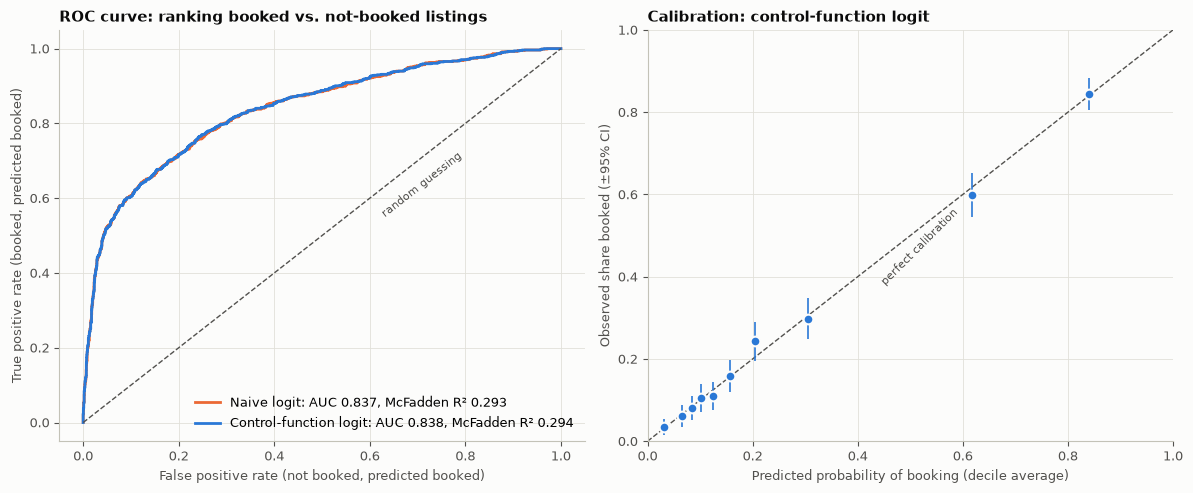

In [29]:
# Stage-2 performance: ROC curve (how well the model ranks booked above not-booked listings)
# and calibration (do predicted probabilities match observed booking rates?). In-sample.
def roc_auc(y, p):
    order = np.argsort(-p)
    y_sorted = y[order]
    tpr = np.concatenate([[0], np.cumsum(y_sorted) / y_sorted.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y_sorted) / (1 - y_sorted).sum()])
    ranks = pd.Series(p).rank().to_numpy()                       # AUC via the Mann-Whitney rank formula
    n1 = y.sum(); n0 = len(y) - n1
    auc = (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    return fpr, tpr, auc

y_b = iv2["booked"].to_numpy()
p_cf, p_naive = cf_logit.predict(iv2).to_numpy(), naive_logit.predict(iv2).to_numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for p, col, name, res in [(p_naive, C_FLAG, "Naive logit", naive_logit), (p_cf, C_BASE, "Control-function logit", cf_logit)]:
    fpr, tpr, auc = roc_auc(y_b, p)
    ax1.plot(fpr, tpr, color=col, lw=2, label=f"{name}: AUC {auc:.3f}, McFadden R² {res.prsquared:.3f}")
ax1.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax1.text(0.62, 0.55, "random guessing", color=MUTED, rotation=38, fontsize=8)
ax1.set_xlabel("False positive rate (not booked, predicted booked)")
ax1.set_ylabel("True positive rate (booked, predicted booked)")
ax1.set_title("ROC curve: ranking booked vs. not-booked listings")
ax1.legend(loc="lower right")

# Calibration: group listings into 10 bins by predicted probability
cal = pd.DataFrame({"p": p_cf, "y": y_b})
cal["bin"] = pd.qcut(cal["p"], 10, labels=False, duplicates="drop")
cal = cal.groupby("bin").agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
se_obs = np.sqrt(cal["obs"] * (1 - cal["obs"]) / cal["n"])
ax2.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax2.text(0.44, 0.38, "perfect calibration", color=MUTED, rotation=45, fontsize=8)
ax2.errorbar(cal["pred"], cal["obs"], yerr=1.96 * se_obs, fmt="o", color=C_BASE, ms=7,
             mec=SURFACE, mew=1.5, elinewidth=1.2, capsize=0)
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)
ax2.set_xlabel("Predicted probability of booking (decile average)")
ax2.set_ylabel("Observed share booked (±95% CI)")
ax2.set_title("Calibration: control-function logit")
fig.tight_layout(); plt.show()

### Technique 5 findings
- **Sample:** 3,216 listings from 587 hosts who list in more than one neighbourhood. 130 more were dropped from neighbourhoods or room types where booking doesn't vary, including all 4 shared rooms, which were all booked. So the model says nothing about shared rooms. These are mostly multi-property operators. Only 25% of their listings were booked in the last 30 days, compared with 44% across all listings, so the results describe this group and may not generalize to single-listing hosts.
- **The instrument is strong.** A 1-log-point higher premium elsewhere raises the listing's own log price by 0.67 (bootstrap 95% CI 0.54 to 0.76), and the first-stage F-statistic is about 130, far above 10.
- **Higher prices lower the chance of being booked.** The control-function coefficient on ln(price) is −0.97 (95% CI −1.62 to −0.43). On average, a 10% price increase lowers the probability of a booking in the last 30 days by about **1.1 percentage points** (95% CI −1.9 to −0.5), from a base of 25%. That is roughly a 4–5% relative drop.
- **We can't conclude that price is endogenous.** The residual coefficient $\rho$ = +0.28 has a 95% CI of −0.32 to 0.90, which includes zero. The naive logit gives a somewhat smaller effect (−0.9 vs. −1.1 percentage points). The control function makes the effect larger, as expected if unseen demand raises both price and bookings, but the difference isn't statistically significant.
- **Caveats:**
  - The instrument fails if host-wide factors (listing quality, marketing skill, a professional operator's reach) affect bookings directly and not only through price.
  - "Booked" is a review-based proxy.
  - The instrument is built from Technique 3 residuals and held fixed across bootstrap draws, so its own estimation error is not included in the bootstrap.

# Summary of findings

**Question:** what drives the nightly price of a Toronto Airbnb listing, and how does price affect whether a listing gets booked? The data covers 16,463 listings with a posted price, from 10,939 hosts in 140 neighbourhoods.

**Preferred model:** log-linear OLS with neighbourhood fixed effects (Technique 3), with standard errors from a host-cluster bootstrap (Technique 2). It explains 71% of the variation in log price. All effects below hold other features and the neighbourhood constant.

### What moves the price

| Factor | Effect on nightly price | Significant at 5%? |
|---|---|---|
| Monthly rental (minimum stay ≥ 28 nights) vs. short-term | **−57%** | Yes |
| Private room vs. entire home | **−41%** | Yes |
| Shared room vs. entire home | **−52%** | Yes |
| Each additional bed | **+25%** | Yes |
| Superhost | −5.5% | Yes |
| Each additional year hosting | +0.4% | Yes |
| Each additional review | −0.04% (≈ −4% per 100 reviews) | Yes |
| Each additional night of maximum stay | +0.005% (≈ +0.5% per 100 nights) | Yes |
| Hotel room vs. entire home | +5% | No |

- **Size, type of space and rental length matter most.** Beds, room type and whether the listing rents short-term or monthly drive most of the price differences between listings. Host-level traits (superhost status, experience, reviews) have small effects.
- **The superhost and reviews effects are small and negative.** That doesn't mean they hurt a listing. These hosts may price competitively to keep occupancy high, and the effects only became negative once short-term and monthly rentals were separated (see the minimum-stay note in the README).

### Location matters
- **Neighbourhoods differ significantly in price.** The most expensive neighbourhood by average price (Bridle Path–Sunnybrook–York Mills, $614) is significantly pricier than the cheapest (York University Heights, $74). Welch t-test: p = 0.04 on price and p < 0.001 on log price. An ANOVA rejects equal prices across all 140 neighbourhoods.
- **The downtown premium is large.** Holding listing features constant, central neighbourhoods charge about **75–80% more** than Agincourt North (the baseline): Bay Street Corridor +81%, Waterfront Communities +78%, Annex +78%, Rosedale–Moore Park +77%, Niagara +74%.
- **Leaving location out misstates the other effects.** Without neighbourhood fixed effects, the private-room discount looks like −51% instead of −41%, because private rooms are concentrated in cheaper neighbourhoods.

### How reliable these results are
- **The price model holds up out of sample.** In 5-fold cross-validation that keeps each host's listings in one fold, the fixed-effects model explains 70% of the variation in log price for listings it never saw (vs. 71% in-sample), so it isn't overfitting. A typical single-listing prediction is still off by about ±57%, so the model explains *what drives* price better than it pins down the price of any one listing.
- **The booking model ranks and calibrates well.** The stage-2 logit has an AUC of 0.84 and a McFadden R² of 0.29, and its predicted booking probabilities closely match the observed booking rates across deciles.
- **The textbook OLS standard errors were too small.** Listings from the same host are correlated, and the host-cluster bootstrap gives standard errors 1.5–2× larger. Every significance call above uses the bootstrap.
- **Outliers don't drive the results.** Only 21 of 1,104 flagged listings look like data errors (e.g. one-bed rooms at $7,000–$9,000 a night). Dropping them, all high-leverage listings, or all influential listings leaves every coefficient's sign and significance unchanged.
- **Minimum stay is measured as monthly vs. short-term.** Treating minimum stay as a count of nights mispriced long-stay rentals badly, so the model uses a yes/no monthly-stay variable instead. That raised R² from 0.61 to 0.71.

### Price and bookings
- **Higher prices lower the chance of being booked.** In a control-function logit for hosts with listings in several neighbourhoods (3,216 listings), a **10% price increase lowers the probability of a booking in the last 30 days by about 1.1 percentage points** (95% CI −1.9 to −0.5), from a base of 25%. That is roughly a 4–5% relative drop.
- **Demand is fairly price-inelastic.** A 10% higher price costs only about 4–5% of bookings, so raising price within a reasonable range likely increases revenue.
- **We can't confirm that price is endogenous.** The test for it isn't significant, and the naive logit gives a similar answer (−0.9 points).

### What this means for a new host
1. **Location is the biggest lever after size and room type.** A comparable unit downtown commands roughly 75–80% more per night than one in the outer suburbs.
2. **Each extra bed adds about 25% to the nightly rate,** and entire homes command about 40% more than private rooms in the same neighbourhood.
3. **Monthly rentals charge less than half the nightly rate of short-term rentals.** Short-term rentals of under 28 nights fall under Toronto's short-term rental rules, so the trade-off between the higher nightly rate and those rules should be weighed.
4. **Building a reputation (superhost status, reviews) doesn't raise the nightly price on its own.** Its value is more likely in occupancy than in rate.

### Limitations
- **This is observational data, so the effects are associations.** Price effects in Techniques 1–4 could still reflect unmeasured features such as amenities, photos or bathrooms.
- **Prices are listed prices on one scrape date,** not prices actually paid, and about 24% of listings had no price and were excluded.
- **The booking analysis has its own limits.** It uses a review-based proxy for bookings. It covers only hosts with listings in more than one neighbourhood, who are mostly multi-property operators. It also relies on host-wide pricing affecting bookings only through price.